# 02a — Enrichissement, bore et concentration en bore critique

**Objectif** : comprendre comment les deux leviers principaux de la réactivité d'un REP, l'**enrichissement**
du combustible (choisi à la conception) et la **concentration en bore** de l'eau (ajustée en exploitation),
agissent sur k∞, puis trouver la **concentration en bore critique**, celle qui donne k∞ = 1.

On reprend la cellule crayon du notebook 01 (UO₂, gaine Zircaloy-4, eau à 580 K et 155 bar, réseau infini) et on
fait varier un paramètre à la fois.

**Plan**
1. k∞ en fonction de l'enrichissement (sans bore), et durcissement du spectre.
2. k∞ et réactivité en fonction de la concentration en bore (UO₂ 4 %), efficacité différentielle du bore.
3. Concentration en bore critique : par ajustement du balayage, puis par la recherche automatique `keff_search`.

## 0. Rappel : réactivité et bilan neutronique

Sans fuites, $k_\infty = P/A$ : production de neutrons par fission divisée par absorption (notebook 01). Les
variations de k s'expriment plutôt en **réactivité** :

$$\rho = \frac{k-1}{k} = 1 - \frac{A}{P} \qquad (\text{en pcm, } 1\ \text{pcm} = 10^{-5})$$

Ce choix n'est pas qu'une convention. Ajouter un absorbant (le bore) ajoute un terme à $A$ sans changer $P$ en
première approximation : $\rho$ diminue alors **linéairement** avec la quantité d'absorbant, tant que la forme du
flux ne change pas. On le vérifiera dans la partie 2.

**Méthode** : chaque point de calcul utilise 10 000 neutrons × 120 générations actives (≈ 1,2 million
d'histoires, environ 1 min). L'incertitude statistique (≈ 80 pcm) est petite devant les effets étudiés (des
milliers de pcm). Le modèle complet est construit par `src/modeles.py` à partir de quelques paramètres, et
`src/calcul.py` lance chaque calcul dans son propre dossier.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmc

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))
from src.modeles import modele_cellule_crayon
from src.materials import eau_boree
from src.calcul import calculer_k, reactivite_pcm

os.environ["PATH"] = str(Path(sys.executable).parent) + os.pathsep + os.environ["PATH"]
os.environ.setdefault(
    "OPENMC_CROSS_SECTIONS", str(Path.home() / "nuclear_data/endfb-viii.0-hdf5/cross_sections.xml")
)
assert Path(os.environ["OPENMC_CROSS_SECTIONS"]).exists(), "Données nucléaires introuvables (voir README)"

DOSSIER_CALCUL = RACINE / "runs" / "02a_enrichissement_bore"
DOSSIER_RESULTATS = RACINE / "results"
STATISTIQUE = dict(particules=10_000, generations=150, inactives=30, graine=1)

print("OpenMC", openmc.__version__)

OpenMC 0.16.0


### Tally de spectre

Pour voir comment le spectre change avec l'enrichissement et le bore, on ajoute à chaque calcul un tally de flux
dans le combustible, découpé en 300 groupes d'énergie (moins fins que dans le notebook 01 : on s'intéresse ici à
la forme globale, pas aux résonances).

In [2]:
BORNES_E = np.logspace(np.log10(1e-5), np.log10(20e6), 301)   # eV
COUPURE_THERMIQUE = 0.625                                      # eV


def ajouter_tally_spectre(modele, cellules):
    tally = openmc.Tally(name="spectre")
    tally.filters = [openmc.CellFilter([cellules["combustible"]]), openmc.EnergyFilter(BORNES_E)]
    tally.scores = ["flux"]
    modele.tallies = openmc.Tallies([tally])


def lire_spectre(statepoint):
    # Flux par groupe dans le combustible, normalisé à 1 (somme sur les groupes)
    with openmc.StatePoint(statepoint) as sp:
        flux = sp.get_tally(name="spectre").mean.ravel()
    return flux / flux.sum()


def fraction_thermique(flux):
    return flux[BORNES_E[1:] <= COUPURE_THERMIQUE].sum()

## 1. Effet de l'enrichissement

L'enrichissement est la proportion massique d'U-235 dans l'uranium : 0,711 % dans l'uranium naturel, 3 à 5 % dans
le combustible des REP. On le fait varier **sans bore**, pour isoler l'effet du combustible.

Ce qu'on attend, avec les facteurs de la formule des quatre facteurs ($k_\infty = \varepsilon\,p\,f\,\eta$) :
- le **facteur de reproduction** η (neutrons produits par neutron absorbé dans le combustible) augmente avec la
  part d'U-235 dans les absorptions, mais il est borné par la valeur de l'U-235 pur (≈ 2,07 en spectre thermique) :
  l'effet doit **saturer** ;
- le **facteur d'utilisation thermique** f (part des neutrons thermiques absorbés dans le combustible plutôt que dans
  l'eau ou la gaine) augmente aussi, et sature également.

In [3]:
enrichissements = [0.711, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0]   # % massique d'U-235

lignes, spectres_enrichissement = [], {}
for e in enrichissements:
    modele, cellules = modele_cellule_crayon(enrichissement=e, bore_ppm=0, **STATISTIQUE)
    ajouter_tally_spectre(modele, cellules)
    r = calculer_k(modele, DOSSIER_CALCUL / f"enrichissement_{e}")
    flux = lire_spectre(r["statepoint"])
    spectres_enrichissement[e] = flux
    lignes.append({"enrichissement_pct": e, "k_inf": r["k"], "sigma": r["sigma"],
                   "fraction_thermique": fraction_thermique(flux)})
    print(f"e = {e:5.3f} %   k∞ = {r['k']:.5f} ± {r['sigma']:.5f}   ({r['duree']:.0f} s)")

df_enrichissement = pd.DataFrame(lignes)
df_enrichissement.to_csv(DOSSIER_RESULTATS / "02a_enrichissement.csv", index=False)

e = 0.711 %   k∞ = 0.88662 ± 0.00070   (24 s)


e = 1.000 %   k∞ = 1.00724 ± 0.00071   (25 s)


e = 1.500 %   k∞ = 1.13538 ± 0.00090   (22 s)


e = 2.000 %   k∞ = 1.21456 ± 0.00088   (21 s)


e = 3.000 %   k∞ = 1.30714 ± 0.00073   (19 s)


e = 4.000 %   k∞ = 1.35844 ± 0.00083   (18 s)


e = 5.000 %   k∞ = 1.39233 ± 0.00098   (18 s)


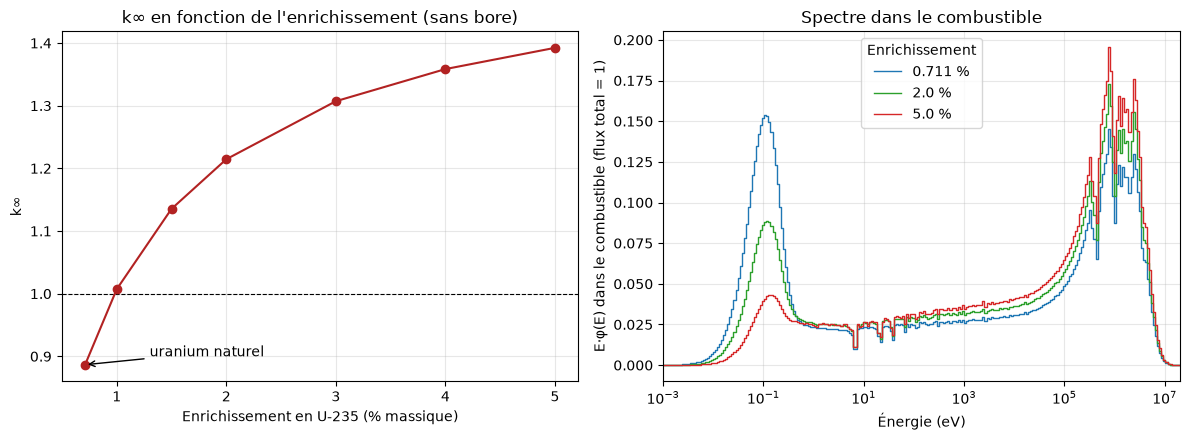

,enrichissement_pct,k_inf,sigma,fraction_thermique
0,0.711000,0.88662,0.00070,30.4%
1,1.000000,1.00724,0.00071,26.4%
2,1.500000,1.13538,0.00090,21.6%
3,2.000000,1.21456,0.00088,18.2%
4,3.000000,1.30714,0.00073,13.9%
5,4.000000,1.35844,0.00083,11.2%
6,5.000000,1.39233,0.00098,9.4%


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.errorbar(df_enrichissement.enrichissement_pct, df_enrichissement.k_inf, yerr=df_enrichissement.sigma,
             fmt="o-", color="firebrick", capsize=3)
ax1.axhline(1, color="k", ls="--", lw=0.8)
ax1.annotate("uranium naturel", xy=(0.711, df_enrichissement.k_inf.iloc[0]), xytext=(1.3, 0.9),
             arrowprops=dict(arrowstyle="->"))
ax1.set_xlabel("Enrichissement en U-235 (% massique)")
ax1.set_ylabel("k∞")
ax1.set_title("k∞ en fonction de l'enrichissement (sans bore)")
ax1.grid(alpha=0.3)

E_milieu = np.sqrt(BORNES_E[:-1] * BORNES_E[1:])
d_lethargie = np.log(BORNES_E[1:] / BORNES_E[:-1])
for e, couleur in [(0.711, "tab:blue"), (2.0, "tab:green"), (5.0, "tab:red")]:
    ax2.step(E_milieu, spectres_enrichissement[e] / d_lethargie, where="mid", color=couleur, lw=1,
             label=f"{e} %")
ax2.set_xscale("log")
ax2.set_xlim(1e-3, 2e7)
ax2.set_xlabel("Énergie (eV)")
ax2.set_ylabel("E·φ(E) dans le combustible (flux total = 1)")
ax2.set_title("Spectre dans le combustible")
ax2.legend(title="Enrichissement")
ax2.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "02a_enrichissement.png", dpi=150, bbox_inches="tight")
plt.show()

df_enrichissement.style.format({"k_inf": "{:.5f}", "sigma": "{:.5f}", "fraction_thermique": "{:.1%}"})

**Interprétation.**

- **Uranium naturel : k∞ < 1**, même sans aucun bore. Avec de l'eau légère comme modérateur, l'hydrogène capture trop
  de neutrons pour que l'uranium naturel entretienne la réaction en chaîne. C'est pour cela que les REP ont besoin
  d'uranium enrichi, alors que les réacteurs modérés à l'eau lourde (CANDU) ou au graphite (UNGG, Magnox)
  fonctionnent à l'uranium naturel : ces modérateurs absorbent beaucoup moins.
- **Saturation** : le gain de k∞ est fort aux faibles enrichissements puis s'amenuise. Passer de 4 à 5 % rapporte
  beaucoup moins que passer de 1 à 2 %. On enrichit pourtant jusqu'à ~5 % : non pas pour augmenter k∞ du combustible
  neuf, mais pour avoir assez d'U-235 pour **durer plus longtemps** en réacteur (taux de combustion plus élevé,
  notebook 04).
- **Durcissement du spectre** : plus il y a d'U-235, plus les neutrons thermiques sont absorbés dans le combustible
  avant d'y « s'accumuler » : la bosse thermique diminue (colonne `fraction_thermique`). Le spectre se décale vers les
  hautes énergies.

## 2. Effet de la concentration en bore

Le bore est dissous dans l'eau du circuit primaire sous forme d'acide borique. C'est l'**isotope B-10**
(19,9 % du bore naturel) qui agit : il absorbe les neutrons thermiques par la réaction
$^{10}\text{B}(n,\alpha)^{7}\text{Li}$, avec une section efficace d'environ 3 800 barns à 0,025 eV qui varie en
$1/v$. Le bore n'agit que sur le **facteur d'utilisation thermique f** : il « vole » des neutrons thermiques au
combustible.

Avantage majeur pour l'exploitation : le bore est réparti **uniformément** dans le cœur (pas de déformation de la
nappe de puissance, contrairement aux barres de commande), et sa concentration se règle en continu par dilution ou
borication.

On balaie de 0 à 6 000 ppm, avec l'UO₂ à 4 %. La plage dépasse largement les valeurs d'exploitation, pour encadrer la
concentration critique de notre réseau infini (voir partie 3).

In [5]:
concentrations = np.arange(0, 6001, 1000)   # ppm (massiques)

lignes, spectres_bore = [], {}
for c in concentrations:
    modele, cellules = modele_cellule_crayon(enrichissement=4.0, bore_ppm=c, **STATISTIQUE)
    ajouter_tally_spectre(modele, cellules)
    r = calculer_k(modele, DOSSIER_CALCUL / f"bore_{c}")
    flux = lire_spectre(r["statepoint"])
    spectres_bore[c] = flux
    rho, sigma_rho = reactivite_pcm(r["k"], r["sigma"])
    lignes.append({"bore_ppm": c, "k_inf": r["k"], "sigma": r["sigma"], "rho_pcm": rho,
                   "sigma_rho_pcm": sigma_rho, "fraction_thermique": fraction_thermique(flux)})
    print(f"C_B = {c:5d} ppm   k∞ = {r['k']:.5f} ± {r['sigma']:.5f}   ρ = {rho:8.0f} ± {sigma_rho:.0f} pcm")

df_bore = pd.DataFrame(lignes)

C_B =     0 ppm   k∞ = 1.35844 ± 0.00083   ρ =    26386 ± 45 pcm


C_B =  1000 ppm   k∞ = 1.26402 ± 0.00085   ρ =    20888 ± 53 pcm


C_B =  2000 ppm   k∞ = 1.18335 ± 0.00085   ρ =    15494 ± 61 pcm


C_B =  3000 ppm   k∞ = 1.11405 ± 0.00074   ρ =    10238 ± 59 pcm


C_B =  4000 ppm   k∞ = 1.05501 ± 0.00088   ρ =     5214 ± 79 pcm


C_B =  5000 ppm   k∞ = 1.00140 ± 0.00072   ρ =      140 ± 72 pcm


C_B =  6000 ppm   k∞ = 0.95502 ± 0.00083   ρ =    -4710 ± 91 pcm


### Ajustement de la réactivité

On ajuste $\rho(C_B)$ par un polynôme, en pondérant chaque point par $1/\sigma$ (les points les plus précis comptent
plus). Pour choisir le degré, on compare un ajustement **linéaire** et un ajustement **quadratique** à l'aide du
$\chi^2$ réduit :

$$\chi^2_\text{réduit} = \frac{1}{N - n_\text{param}} \sum_i \left( \frac{\rho_i - \rho_\text{ajusté}(C_i)}{\sigma_i} \right)^2$$

Un modèle adapté donne $\chi^2_\text{réduit} \approx 1$ : les écarts aux points sont du même ordre que les barres
d'erreur. Une valeur bien plus grande signifie que le modèle ne suit pas la physique.

In [6]:
C, rho, s_rho = df_bore.bore_ppm.values, df_bore.rho_pcm.values, df_bore.sigma_rho_pcm.values

ajustements = {}
for degre in (1, 2):
    # cov="unscaled" : la covariance des coefficients vient directement des σ donnés
    coefs, cov = np.polyfit(C, rho, degre, w=1 / s_rho, cov="unscaled")
    residus = (rho - np.polyval(coefs, C)) / s_rho
    chi2_reduit = np.sum(residus**2) / (len(C) - (degre + 1))
    ajustements[degre] = (coefs, cov, residus)
    print(f"Degré {degre} : χ² réduit = {chi2_reduit:7.1f}")

coefs, cov, residus = ajustements[2]   # le modèle retenu (justifié ci-dessous)
efficacite = np.polyder(coefs)          # dρ/dC_B en pcm/ppm
for c in (0, 1000, 2000, 5000):
    print(f"Efficacité différentielle du bore à {c:4d} ppm : {np.polyval(efficacite, c):6.2f} pcm/ppm")

Degré 1 : χ² réduit =    17.1
Degré 2 : χ² réduit =     0.3
Efficacité différentielle du bore à    0 ppm :  -5.57 pcm/ppm
Efficacité différentielle du bore à 1000 ppm :  -5.44 pcm/ppm
Efficacité différentielle du bore à 2000 ppm :  -5.31 pcm/ppm
Efficacité différentielle du bore à 5000 ppm :  -4.92 pcm/ppm


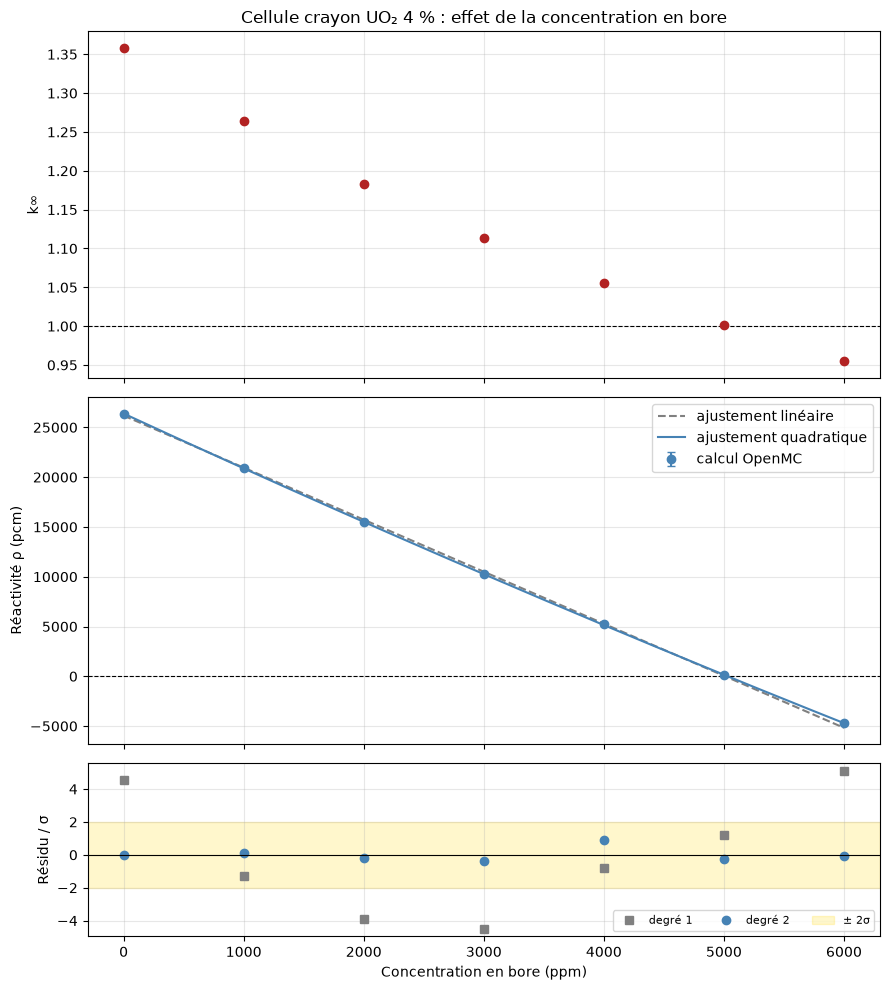

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True, gridspec_kw={"height_ratios": [2, 2, 1]})
C_fin = np.linspace(0, 6000, 300)

axes[0].errorbar(C, df_bore.k_inf, yerr=df_bore.sigma, fmt="o", color="firebrick", capsize=3)
axes[0].axhline(1, color="k", ls="--", lw=0.8)
axes[0].set_ylabel("k∞")
axes[0].set_title("Cellule crayon UO₂ 4 % : effet de la concentration en bore")

axes[1].errorbar(C, rho, yerr=s_rho, fmt="o", color="steelblue", capsize=3, label="calcul OpenMC")
axes[1].plot(C_fin, np.polyval(ajustements[1][0], C_fin), "--", color="gray", label="ajustement linéaire")
axes[1].plot(C_fin, np.polyval(coefs, C_fin), color="steelblue", label="ajustement quadratique")
axes[1].axhline(0, color="k", ls="--", lw=0.8)
axes[1].set_ylabel("Réactivité ρ (pcm)")
axes[1].legend()

for degre, (marqueur, couleur) in {1: ("s", "gray"), 2: ("o", "steelblue")}.items():
    axes[2].plot(C, ajustements[degre][2], marqueur, color=couleur, label=f"degré {degre}")
axes[2].axhspan(-2, 2, color="gold", alpha=0.2, label="± 2σ")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_ylabel("Résidu / σ")
axes[2].set_xlabel("Concentration en bore (ppm)")
axes[2].legend(ncol=3, fontsize=8)

for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "02a_bore.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation.**

- k∞ décroît avec le bore, mais pas linéairement. La **réactivité**, elle, est presque une droite : c'est la
  justification du choix de ρ annoncé en partie 0.
- Le « presque » se lit sur les **résidus** (en bas). L'ajustement linéaire laisse des écarts **systématiques**
  de 4 à 5σ, en forme de U (positifs aux deux extrémités, négatifs au milieu), et un χ² réduit d'environ 17 :
  une droite ne décrit pas les points. L'ajustement quadratique ramène tous les résidus à moins de 1σ : la
  courbure est réelle.
- Son χ² réduit (≈ 0,3) est même un peu inférieur à 1. Avec seulement 4 degrés de liberté (7 points,
  3 paramètres), ce n'est pas anormal. Il faut aussi savoir que les 7 calculs utilisent la **même graine**
  aléatoire : leurs fluctuations statistiques sont donc en partie corrélées, ce qui peut lisser la courbe. Cela
  invite à rester prudent sur l'incertitude de la concentration critique déduite de l'ajustement, d'où l'intérêt
  de la vérifier par une seconde méthode (partie 3.2).
- **Pourquoi cette courbure ?** L'efficacité du bore diminue quand sa concentration augmente (de l'ordre de 5 pcm/ppm
  ici, en valeur absolue, un peu moins à forte concentration). Plus il y a de bore, moins il reste de neutrons
  thermiques à capturer : le spectre se **durcit**, et un absorbant en $1/v$ devient moins efficace. On le voit dans
  la colonne `fraction_thermique` ci-dessous.

In [8]:
df_bore.to_csv(DOSSIER_RESULTATS / "02a_bore.csv", index=False)
df_bore.style.format({"k_inf": "{:.5f}", "sigma": "{:.5f}", "rho_pcm": "{:.0f}", "sigma_rho_pcm": "{:.0f}",
                      "fraction_thermique": "{:.1%}"})

,bore_ppm,k_inf,sigma,rho_pcm,sigma_rho_pcm,fraction_thermique
0,0,1.35844,0.00083,26386,45,11.2%
1,1000,1.26402,0.00085,20888,53,10.5%
2,2000,1.18335,0.00085,15494,61,9.7%
3,3000,1.11405,0.00074,10238,59,9.1%
4,4000,1.05501,0.00088,5214,79,8.6%
5,5000,1.00140,0.00072,140,72,8.1%
6,6000,0.95502,0.00083,-4710,91,7.7%


## 3. Concentration en bore critique

### 3.1 Par l'ajustement

La concentration critique $C^*$ est la racine de $\rho(C) = 0$ sur l'ajustement quadratique. Son incertitude se
déduit de celle des coefficients de l'ajustement par **propagation linéaire** : si $\rho(C) = aC^2 + bC + c$,

$$\sigma_{C^*}^2 = \frac{g^\mathsf{T}\, \mathrm{Cov}\, g}{\left(\partial\rho/\partial C\right)^2_{C^*}}
\qquad \text{avec } g = (C^{*2},\ C^*,\ 1)$$

Autrement dit : l'incertitude sur la réactivité au voisinage de $C^*$, divisée par la pente.

In [9]:
racines = np.roots(coefs)
C_critique = float(np.real(racines[(np.isreal(racines)) & (racines > 0) & (racines < 10_000)][0]))
g = np.array([C_critique**2, C_critique, 1.0])
pente = np.polyval(efficacite, C_critique)
sigma_C_critique = np.sqrt(g @ cov @ g) / abs(pente)

print(f"Concentration critique (ajustement) : C* = {C_critique:.0f} ± {sigma_C_critique:.0f} ppm  (1σ)")

Concentration critique (ajustement) : C* = 5032 ± 9 ppm  (1σ)


### 3.2 Par la recherche automatique `keff_search`

OpenMC 0.16 propose `Model.keff_search`, qui implémente la méthode **GRsecant** (Price et Roskoff, 2023). C'est une
méthode de la sécante (on trace une droite entre deux points et on vise son zéro) adaptée au bruit statistique :

- le point suivant est prédit par un **ajustement linéaire pondéré** des derniers calculs, et non par les deux
  derniers points seulement ;
- le **nombre de générations augmente** à mesure qu'on s'approche de la solution : inutile de calculer avec précision
  un point loin du but, mais indispensable près du but.

L'exemple officiel *Criticality Search* utilise l'ancienne fonction `openmc.search_for_keff` avec une bisection : avec
une incertitude par point plus grande que les écarts entre les dernières itérations, ces dernières itérations y
suivent le bruit. Il définit aussi le bore en fraction atomique au lieu d'une fraction massique, ce qui ne met que
60 % du bore annoncé ; on utilise ici `borated_water`, qui interprète correctement les ppm massiques.

`keff_search` demande une fonction qui **modifie le modèle en place** : ici, elle remplace l'eau du modérateur par
une eau à la nouvelle concentration.

Critères d'arrêt choisis : $|k - 1| < 2 \cdot 10^{-4}$ (20 pcm) avec une incertitude finale inférieure à 50 pcm.

On lui donne comme points de départ 4 000 et 6 000 ppm, avec les mêmes réglages et la même graine que le balayage :
ses deux premières itérations doivent donc redonner **exactement** les k du balayage à ces concentrations. C'est un
test simple de reproductibilité.

> **Reproductibilité d'une recherche itérative.** Sur plusieurs cœurs, OpenMC additionne les contributions des
> différents fils de calcul dans un ordre variable : deux calculs identiques donnent des k qui diffèrent au
> 14ᵉ chiffre. C'est sans effet sur un calcul isolé. Mais `keff_search` utilise ces k pour choisir la concentration
> suivante : l'écart passe dans la composition de l'eau (vers le 10ᵉ chiffre), ce qui suffit à faire basculer un
> seul tirage aléatoire d'un neutron. Son histoire change, donc les sites de fission, donc la source de la génération
> suivante : on obtient un **autre tirage statistique**, aussi valable mais différent (nous l'avons constaté : jusqu'à
> 200 pcm d'écart dès la 4ᵉ itération, et 5029 ppm contre 5033 ppm au final).
> Remède : **arrondir la concentration à 0,1 ppm** avant de l'appliquer, ce qui efface ces écarts infimes. Le chemin
> de la recherche devient alors identique d'une exécution à l'autre (vérifié sur deux exécutions).

In [10]:
modele_recherche, cellules_recherche = modele_cellule_crayon(enrichissement=4.0, bore_ppm=C_critique, **STATISTIQUE)


def regler_bore(ppm):
    # Arrondi à 0,1 ppm : garantit la reproductibilité (voir l'encadré ci-dessus)
    cellules_recherche["moderateur"].fill = eau_boree(round(ppm, 1))
    modele_recherche.materials = openmc.Materials([c.fill for c in cellules_recherche.values()])


dossier_recherche = DOSSIER_CALCUL / "recherche"
dossier_recherche.mkdir(parents=True, exist_ok=True)
recherche = modele_recherche.keff_search(
    regler_bore, 4000, 6000, k_tol=2e-4, sigma_final=5e-4,
    run_kwargs={"cwd": dossier_recherche, "output": False},
)

# keff_search stocke k − cible ; on rajoute la cible (1) pour afficher k
df_recherche = pd.DataFrame({
    "iteration": range(1, recherche.function_calls + 1),
    "bore_ppm": recherche.parameters,
    "k_inf": np.array(recherche.means) + 1.0,
    "sigma": recherche.stdevs,
    "generations_actives": recherche.batches,
})
print(f"Résultat : {recherche.root:.0f} ppm — convergé : {recherche.converged} ({recherche.flag}), "
      f"{recherche.function_calls} calculs, {recherche.total_batches} générations actives au total")
df_recherche.style.format({"bore_ppm": "{:.1f}", "k_inf": "{:.5f}", "sigma": "{:.5f}"})

Résultat : 5029 ppm — convergé : True (converged), 9 calculs, 1333 générations actives au total


,iteration,bore_ppm,k_inf,sigma,generations_actives
0,1,4000.0,1.05501,0.00088,150
1,2,6000.0,0.95502,0.00083,150
2,3,5100.3,0.99547,0.00180,50
3,4,5091.1,0.99592,0.00138,55
4,5,5079.1,0.99647,0.00162,56
5,6,5000.2,1.00064,0.00125,62
6,7,5012.4,1.00132,0.00065,204
7,8,5027.7,1.00023,0.00073,178
8,9,5029.3,1.00013,0.00042,428


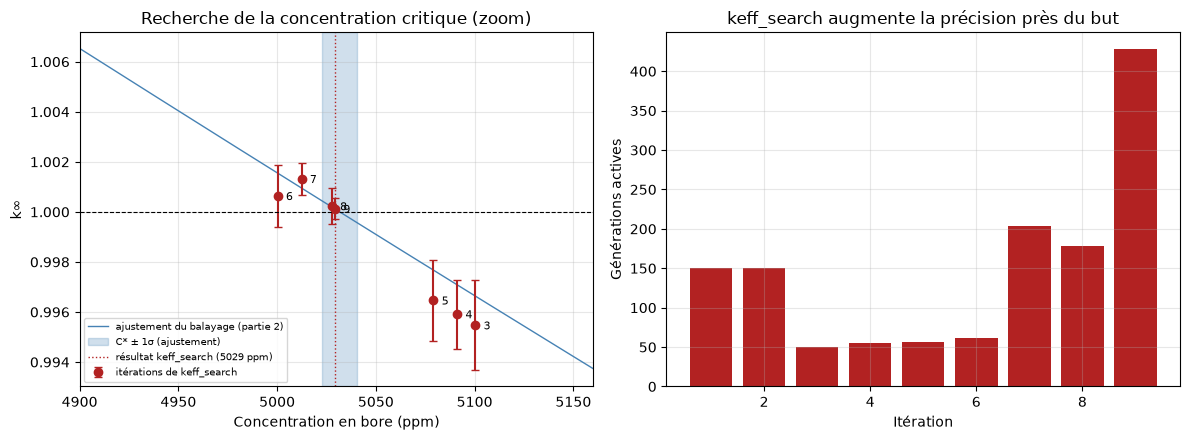

Ajustement   : 5032 ± 9 ppm
keff_search  : 5029 ppm
Écart        : -2 ppm, soit -0.3 σ de l'ajustement


In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Zoom sur la zone de la solution ; k(C) déduit de l'ajustement quadratique de ρ en référence
C_zoom = np.linspace(4900, 5160, 200)
ax1.plot(C_zoom, 1 / (1 - np.polyval(coefs, C_zoom) * 1e-5), color="steelblue", lw=1,
         label="ajustement du balayage (partie 2)")
ax1.axvspan(C_critique - sigma_C_critique, C_critique + sigma_C_critique, color="steelblue", alpha=0.25,
            label="C* ± 1σ (ajustement)")
proches = df_recherche[df_recherche.bore_ppm.between(4900, 5160)]
ax1.errorbar(proches.bore_ppm, proches.k_inf, yerr=proches.sigma, fmt="o", color="firebrick", capsize=3,
             label="itérations de keff_search")
for _, ligne in proches.iterrows():
    ax1.annotate(int(ligne.iteration), (ligne.bore_ppm, ligne.k_inf), textcoords="offset points", xytext=(6, -3),
                 fontsize=8)
ax1.axhline(1, color="k", ls="--", lw=0.8)
ax1.axvline(recherche.root, color="firebrick", ls=":", lw=1, label=f"résultat keff_search ({recherche.root:.0f} ppm)")
ax1.set_xlim(4900, 5160)
ax1.set_xlabel("Concentration en bore (ppm)")
ax1.set_ylabel("k∞")
ax1.set_title("Recherche de la concentration critique (zoom)")
ax1.legend(fontsize=7, loc="lower left")

ax2.bar(df_recherche.iteration, df_recherche.generations_actives, color="firebrick")
ax2.set_xlabel("Itération")
ax2.set_ylabel("Générations actives")
ax2.set_title("keff_search augmente la précision près du but")

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "02a_bore_critique.png", dpi=150, bbox_inches="tight")
plt.show()

ecart = recherche.root - C_critique
print(f"Ajustement   : {C_critique:.0f} ± {sigma_C_critique:.0f} ppm")
print(f"keff_search  : {recherche.root:.0f} ppm")
print(f"Écart        : {ecart:+.0f} ppm, soit {ecart / sigma_C_critique:+.1f} σ de l'ajustement")

### 3.3 Interprétation : pourquoi si haut ?

Les deux méthodes indépendantes donnent une concentration critique d'environ **5 000 ppm**, compatibles entre elles.
C'est beaucoup plus que dans un REP réel, où la concentration en bore en début de cycle est typiquement de l'ordre
de 1 000 à 2 000 ppm. Ce n'est pas une erreur : c'est la différence entre notre modèle et un cœur.

Notre cellule crayon est un **réseau infini de combustible neuf, sans xénon** : c'est le cas le plus réactif possible.
Dans un cœur réel, plusieurs effets consomment de la réactivité que le bore n'a donc pas à compenser :
- les **fuites** de neutrons hors du cœur ($k_\text{eff} < k_\infty$) ;
- le **combustible déjà irradié** : à chaque rechargement, seule une partie des assemblages est neuve ;
- l'**empoisonnement** par les produits de fission xénon-135 et samarium-149, à l'équilibre en puissance ;
- les **poisons consommables** (gadolinium) placés dans certains crayons ;
- les **grappes de commande** partiellement insérées.

Enfin, la concentration en bore est **limitée** en exploitation : à forte concentration, le coefficient de
température du modérateur peut devenir positif (l'eau qui se dilate perd aussi du bore), ce qui est interdit. C'est
l'objet du notebook 02b.

In [12]:
pd.DataFrame([{
    "enrichissement_pct": 4.0,
    "C_critique_ajustement_ppm": round(C_critique),
    "sigma_ppm": round(sigma_C_critique),
    "C_critique_keff_search_ppm": round(recherche.root),
    "efficacite_bore_1000ppm_pcm_par_ppm": round(np.polyval(efficacite, 1000), 2),
}]).to_csv(DOSSIER_RESULTATS / "02a_bore_critique.csv", index=False)

## 4. Bilan

- **Enrichissement** : k∞ augmente avec la teneur en U-235 puis sature ; l'uranium naturel ne suffit pas avec de
  l'eau légère (k∞ < 1). Plus d'U-235 durcit le spectre.
- **Bore** : la réactivité décroît presque linéairement avec la concentration. La légère courbure, démontrée par
  l'analyse des résidus, vient du durcissement du spectre, qui réduit l'efficacité différentielle du bore.
- **Concentration critique** : environ 5 000 ppm pour un réseau infini de combustible neuf à 4 %, obtenue par
  deux méthodes indépendantes (ajustement avec incertitude, et recherche GRsecant `keff_search`) qui concordent.

**Suite** : notebook 02b, coefficient de température du modérateur et son évolution avec le bore.

## Sources

- Documentation OpenMC 0.16 : `openmc.Model.keff_search`, `openmc.model.borated_water`
  (<https://docs.openmc.org/>).
- Price et Roskoff, *Progress in Nuclear Energy* (2023), article de la méthode GRsecant cité par la
  documentation de `keff_search` : <https://doi.org/10.1016/j.pnucene.2023.104731>.
- Exemple officiel *Criticality Search* (`openmc-notebooks/search.ipynb`), dont on reprend le principe du modèle
  paramétré.